In [1]:
import pandas as pd

# 1. Load datasets

df = pd.read_parquet(r"C:\Users\Gafoo\Downloads\NYC Taxi Analytics\data\raw\yellow_tripdata_2025-03.parquet")
zones = pd.read_csv(r"C:\Users\Gafoo\Downloads\NYC Taxi Analytics\data\raw\taxi_zone_lookup.csv")



In [ ]:
import sys

print(sys.executable)

c:\Users\Gafoo\Downloads\NYC Taxi Analytics\.venv\Scripts\python.exe


: 

**2. Understand dataset size**

In [3]:
df.shape

(4145257, 20)

**3. View first five records**

In [30]:
df.head(5)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-03-01 00:17:16,2025-03-01 00:25:52,1.0,0.90,1.0,N,140,236,1,7.9,3.50,0.5,2.60,0.0,1.0,15.50,2.5,0.0,0.00
1,1,2025-03-01 00:37:38,2025-03-01 00:43:51,1.0,0.60,1.0,N,140,262,1,6.5,3.50,0.5,2.30,0.0,1.0,13.80,2.5,0.0,0.00
2,2,2025-03-01 00:24:35,2025-03-01 00:39:49,1.0,1.94,1.0,N,161,68,1,14.9,1.00,0.5,5.16,0.0,1.0,25.81,2.5,0.0,0.75
3,2,2025-03-01 00:56:16,2025-03-01 01:01:35,2.0,0.95,1.0,N,231,13,1,7.2,1.00,0.5,2.59,0.0,1.0,15.54,2.5,0.0,0.75
4,1,2025-03-01 00:01:44,2025-03-01 00:10:00,1.0,1.50,1.0,N,163,236,1,8.6,4.25,0.5,2.85,0.0,1.0,17.20,2.5,0.0,0.75


**4. Understand columns and data types**

In [31]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee']

In [32]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

**5. Check missing values**

In [6]:
df.isnull().sum().sort_values(ascending=False)

passenger_count          916663
congestion_surcharge     916663
store_and_fwd_flag       916663
RatecodeID               916663
Airport_fee              916663
tpep_dropoff_datetime         0
VendorID                      0
tpep_pickup_datetime          0
DOLocationID                  0
payment_type                  0
trip_distance                 0
PULocationID                  0
extra                         0
fare_amount                   0
mta_tax                       0
tip_amount                    0
improvement_surcharge         0
tolls_amount                  0
total_amount                  0
cbd_congestion_fee            0
dtype: int64

**Check missing value percentages**

In [36]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

passenger_count          22.113538
congestion_surcharge     22.113538
store_and_fwd_flag       22.113538
RatecodeID               22.113538
Airport_fee              22.113538
tpep_dropoff_datetime     0.000000
VendorID                  0.000000
tpep_pickup_datetime      0.000000
DOLocationID              0.000000
payment_type              0.000000
trip_distance             0.000000
PULocationID              0.000000
extra                     0.000000
fare_amount               0.000000
mta_tax                   0.000000
tip_amount                0.000000
improvement_surcharge     0.000000
tolls_amount              0.000000
total_amount              0.000000
cbd_congestion_fee        0.000000
dtype: float64

My observation: All five columns have exactly the same number of missing values.

These missing values may be associated with a particular group of records or a change in the source data structure.

**7. Check duplicate records**

In [37]:
df.duplicated().sum()

np.int64(0)

**8. Statistical summary**

In [38]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
VendorID,4145257.0,1.824944,1.0,2.0,2.0,2.0,7.0,0.549077
tpep_pickup_datetime,4145257,2025-03-16 13:03:28.198472,2007-12-05 18:45:00,2025-03-08 16:22:48,2025-03-16 03:02:13,2025-03-24 09:14:15,2025-04-01 00:00:17,NaN
tpep_dropoff_datetime,4145257,2025-03-16 13:19:27.549571,2007-12-05 19:02:00,2025-03-08 16:39:00,2025-03-16 03:15:59,2025-03-24 09:31:00,2025-04-03 14:07:50,NaN
passenger_count,3228594.0,1.29112,0.0,1.0,1.0,1.0,9.0,0.73175
trip_distance,4145257.0,6.5841,0.0,1.03,1.8,3.42,320136.29,626.407537
RatecodeID,3228594.0,2.423492,1.0,1.0,1.0,1.0,99.0,11.3601
PULocationID,4145257.0,161.765313,1.0,114.0,161.0,232.0,265.0,65.921996
DOLocationID,4145257.0,161.228734,1.0,107.0,162.0,233.0,265.0,70.132795
payment_type,4145257.0,0.956095,0.0,1.0,1.0,1.0,4.0,0.736272
fare_amount,4145257.0,17.800343,-999.0,8.6,13.5,21.25,46263.88,29.101441


1. Maximum recorded trip distance 320,136.29 miles

   This is an extreme value and may be an invalid trip or data-entry issue.

2. Minimum recorded fare -$999

   Negative fares need investigation. They could represent adjustments or unusual transactions.

3. Minimum recorded total_amount -$1,000

   We need to understand whether these are refunds, corrections or invalid records.

4. Minimum pickup year  2027

   Our reporting period is March 2025. This timestamp is suspicious.

**9. Inspect taxi zones**

In [39]:
zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


# 2: Investigate data quality

**1. Check pickup and drop-off date range**

In [41]:
print("Minimum pickup:", df['tpep_pickup_datetime'].min())
print("Maximum pickup:", df['tpep_pickup_datetime'].max())

Minimum pickup: 2007-12-05 18:45:00
Maximum pickup: 2025-04-01 00:00:17


In [43]:
print("Minimum dropoff:", df['tpep_dropoff_datetime'].min())
print("Maximun dropoff:", df['tpep_dropoff_datetime'].max())

Minimum dropoff: 2007-12-05 19:02:00
Maximun dropoff: 2025-04-03 14:07:50


**2. Check pickup records by date**

In [47]:
df.groupby(df['tpep_pickup_datetime'].dt.date).size()

tpep_pickup_datetime
2007-12-05         1
2009-01-01         1
2025-02-28        29
2025-03-01    164225
2025-03-02    128857
2025-03-03    111319
2025-03-04    125887
2025-03-05    148102
2025-03-06    146400
2025-03-07    137877
2025-03-08    147698
2025-03-09    117402
2025-03-10    105213
2025-03-11    125981
2025-03-12    138868
2025-03-13    156893
2025-03-14    145063
2025-03-15    152910
2025-03-16    118920
2025-03-17    112592
2025-03-18    125058
2025-03-19    128292
2025-03-20    153239
2025-03-21    134581
2025-03-22    142104
2025-03-23    121065
2025-03-24    110918
2025-03-25    119934
2025-03-26    131537
2025-03-27    142834
2025-03-28    136362
2025-03-29    163096
2025-03-30    136781
2025-03-31    115216
2025-04-01         2
dtype: int64

There are two different issues here:
- The two historical records are clearly outside our reporting period.
- The February and April records may be valid source records but are outside our March reporting scope.

Our decision: Exclude records with pickup timestamps outside March 2025 from the March reporting dataset, but preserve the original raw data.

**3. Check invalid trip distances**

In [50]:
print("Zero distance:", (df['trip_distance'] == 0).sum())
print("Negative distance:", (df['trip_distance'] < 0).sum())
print("Distance above 100 miles:", (df['trip_distance'] > 100).sum())

Zero distance: 103722
Negative distance: 0
Distance above 100 miles: 214


Zero-distance trips need investigation. They could be cancelled trips, meter errors or unusual short trips.

The 214 trips above 100 miles should also be inspected. Some may be legitimate airport or long-distance trips.

Our decision: Flag these records first. Don't automatically remove all zero-distance or long-distance trips.

**4. Check fare amounts**

In [52]:
print("Negative fares:", (df['fare_amount'] < 0).sum())
print("Zero fares:", (df['fare_amount'] == 0).sum())
print("Fares above $500:", (df['fare_amount'] > 500).sum())

Negative fares: 208724
Zero fares: 1654
Fares above $500: 46


Negative fares may represent refunds, reversals or adjustments. We need to investigate their payment types and other fare components.

Zero fares may represent complimentary, cancelled or unusual transactions.

Fares above $500 are rare, but some long-distance trips could legitimately have high fares.

Our decision: Investigate negative and extreme fares before deciding how to handle them in revenue KPIs.

**5. Check passenger count**

In [56]:
print(df['passenger_count'].value_counts(dropna=False).sort_index())

passenger_count
0.0      22715
1.0    2569487
2.0     442696
3.0     100511
4.0      64214
5.0      18616
6.0      10342
7.0          4
8.0          7
9.0          2
NaN     916663
Name: count, dtype: int64


Observations:
- One passenger is the most common.
- 22,715 records have zero passengers.
- 13 records report 7–9 passengers.
- 916,663 records have missing passenger counts.
We should not assume every zero or high passenger count is invalid. We'll investigate the source definitions and patterns.

**6. Check payment type**

In [54]:
print(df['payment_type'].value_counts(dropna=False).sort_index())

payment_type
0     916663
1    2704166
2     405847
3      26924
4      91657
Name: count, dtype: int64


Payment type 0 appears exactly 916,663 times, matching the missing-value counts in the five columns.

This strongly suggests a common record group, likely associated with missing or unknown fields in the source.

We should check the official data dictionary before assigning business meanings to these codes. In particular, don't interpret payment type 0 as cash.

**7. Check invalid timestamps**

In [57]:
invalid_duration = (
    df["tpep_dropoff_datetime"]
    < df["tpep_pickup_datetime"]
)

print("Dropoff before pickup:", invalid_duration.sum())

Dropoff before pickup: 81


**8. Check missing values together**

In [59]:
df[df['passenger_count'].isna()][["passenger_count", "RatecodeID",
      "store_and_fwd_flag",
      "congestion_surcharge", "Airport_fee"]].head()

,passenger_count,RatecodeID,store_and_fwd_flag,congestion_surcharge,Airport_fee
3228594,NaN,NaN,NaN,NaN,NaN
3228595,NaN,NaN,NaN,NaN,NaN
3228596,NaN,NaN,NaN,NaN,NaN
3228597,NaN,NaN,NaN,NaN,NaN
3228598,NaN,NaN,NaN,NaN,NaN


**9. Check March pickup dates**

In [60]:
outside_march = ~df['tpep_pickup_datetime'].between("2025-03-01","2025-03-31 23:59:59")

print("Outside March pickup records:", outside_march.sum())


Outside March pickup records: 33


# Advanced investigation before cleaning

**Investigate missing-value patterns**

In [61]:
missing_col = ["passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"]

#  How many rows have all five fields missing?

print("All five missing", df[missing_col].isna().all(axis=1).sum())

All five missing 916663


In [62]:
# Relationship between payment type and missing values

print(pd.crosstab(df['payment_type'],df['passenger_count'].isna()))

passenger_count    False   True 
payment_type                    
0                      0  916663
1                2704166       0
2                 405847       0
3                  26924       0
4                  91657       0


All five columns are missing in exactly the same 916,663 records.

What does this tell us?
- Every record with payment type 0 has all five fields missing.
- Every record with payment types 1–4 has passenger count populated.
- This is a systematic missing-value pattern, not five independent missing-value problems.
Our decision: Do not delete these 916,663 records. They may contain valid trip and fare information. We should preserve them and investigate their payment-type meaning.

**Investigate negative fares**

In [69]:
negative_fares = df[df['fare_amount'] < 0]

print("Negative fare records:",
      len(negative_fares))

print("\nPayment type distribution:")
print(negative_fares['payment_type'].value_counts())

print("\nNegative fare statistics:")
print(negative_fares[["fare_amount", "total_amount", "trip_distance"]].describe())

Negative fare records: 208724

Payment type distribution:
payment_type
0    140460
4     42879
2     16648
3      8712
1        25
Name: count, dtype: int64

Negative fare statistics:
         fare_amount   total_amount  trip_distance
count  208724.000000  208724.000000  208724.000000
mean      -10.157447      -6.226472      18.613553
std        17.179856      22.259656    1452.616469
min      -999.000000   -1000.000000       0.000000
25%        -7.900000     -12.350000       1.000000
50%        -4.750000       3.000000       2.000000
75%        -4.750000       4.870000       3.930000
max        -0.010000      80.000000  320136.290000


Some interesting findings:
- Payment type 0 accounts for the largest number of negative fares.
- Payment type 4 is also strongly represented.
- Median negative fare is -$4.75.
- Mean negative fare is -$10.16.
- Minimum fare is -$999.
The combination of negative fares and negative total amounts suggests refunds, reversals or adjustments may be present.

However, we cannot confirm the exact transaction reason from these statistics alone.

Our decision: Keep these records in the raw dataset. Create a negative-fare flag and investigate their transaction components before deciding how they contribute to revenue.

**Investigate zero-distance trips**

In [ ]:
zero_distance = df[df['trip_distance'] == 0]

print("Zero distance records:", len(zero_distance))

print("\nFare statistics:")
print(zero_distance[["fare_amount", "total_amount", "tip_amount","trip_distance"]].describe())

print("\nPayment Types:")
print(zero_distance['payment_type'].value_counts())

# Payment type 0 means Flex Fare trip, not unknown payment.

Zero distance records: 103722

Fare statistics:
         fare_amount   total_amount     tip_amount  trip_distance
count  103722.000000  103722.000000  103722.000000       103722.0
mean       19.216980      25.079630       1.509997            0.0
std        30.401183      33.637876       5.234722            0.0
min      -500.000000    -501.000000     -50.000000            0.0
25%         3.000000       8.750000       0.000000            0.0
50%        14.780000      19.770000       0.000000            0.0
75%        25.400000      30.540000       0.000000            0.0
max       990.000000    1249.300000     290.000000            0.0

Payment Types:
payment_type
0    61816
1    21366
2     9211
4     6249
3     5080
Name: count, dtype: int64


- Minimum fare: -$500
- Median fare: $14.78
- Maximum fare: $990
- Maximum total amount: $1,249.30
This is particularly interesting.

A zero-distance trip with a positive fare might be a cancelled or interrupted trip, a meter issue or an unusual transaction.

We should not automatically classify every zero-distance trip as invalid.

**Investigate high-value trips**

In [73]:
high_fares = df[df['fare_amount'] > 500]

print("High fare records: ", len(high_fares))

print(high_fares[["trip_distance", "fare_amount",
     "total_amount", "payment_type"]].head(20))

High fare records:  46
        trip_distance  fare_amount  total_amount  payment_type
57248          251.45      1676.00       1694.31             2
133960         190.50       650.00        832.74             1
172876           0.03       999.00       1000.00             4
270664          87.60       552.50        570.39             2
342490         116.42       834.60       1015.55             1
404429           8.49       740.00        741.00             1
453349         102.75       600.00        731.28             1
453891          24.21       801.00        806.75             2
492414          33.10       600.00        602.75             1
757548           0.00       600.00        601.00             1
757549           0.00       600.00        601.00             1
848657         161.80      1026.40       1059.21             2
851957        1191.90     46263.88      46269.44             2
908338          82.82       556.70        698.59             1
933942           0.00       700.

The transaction with 1,191.90 miles and a $46,263.88 fare is particularly suspicious.

Also, a $999 fare for a 0.03-mile trip needs investigation.

Our decision: Flag these transactions and investigate them individually. Don't apply an arbitrary $500 maximum fare to every trip

**Calculate trip duration**

In [76]:
df['trip_duration_minutes'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60

print(df['trip_duration_minutes'].describe())

print("Negative duration:",
      (df["trip_duration_minutes"] < 0).sum())

print("Zero duration:",
      (df["trip_duration_minutes"] == 0).sum())

print("Duration above 24 hours:",
      (df["trip_duration_minutes"] > 1440).sum())

count    4.145257e+06
mean     1.598918e+01
std      2.729762e+01
min     -3.431667e+01
25%      7.716667e+00
50%      1.246667e+01
75%      1.946667e+01
max      6.275833e+03
Name: trip_duration_minutes, dtype: float64
Negative duration: 81
Zero duration: 22199
Duration above 24 hours: 11


We have three distinct issues:
1. Negative duration: logically invalid.
2. Zero duration: potentially cancelled trips, timestamp errors or unusual records.
3. More than 24 hours: suspicious and needs investigation.
For our duration KPIs, we'll exclude invalid negative durations. Zero-duration and unusually long trips will be flagged pending investigation.

## Data Cleaning

**1: Keep only March 2025 records**

Our dataset contains a few records from February, April, and even older years.

But our project focuses only on March 1–31, 2025. So we'll filter out records outside that period.

In [80]:
# Filter trips from March 1 to March 31, 2025

df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])

march_df = df[(df['tpep_pickup_datetime'] >= "2025-03-01") & (df['tpep_pickup_datetime'] < "2025-04-1")].copy()

print("Original rows: ", len(df))
print("March 2025 rows:", len(march_df))

print("Minimum pickup date:", march_df["tpep_pickup_datetime"].min())
print("Maximum pickup date:", march_df["tpep_pickup_datetime"].max())


Original rows:  4145257
March 2025 rows: 4145224
Minimum pickup date: 2025-03-01 00:00:00
Maximum pickup date: 2025-03-31 23:59:59


**2: Check missing values**

In [82]:
missing_values = march_df.isnull().sum()
print(missing_values[missing_values > 0])


passenger_count         916663
RatecodeID              916663
store_and_fwd_flag      916663
congestion_surcharge    916663
Airport_fee             916663
dtype: int64


**3: Check duplicate records**

In [83]:

# Check duplicate records

duplicates = march_df.duplicated().sum()

print("Duplicate records:", duplicates)


Duplicate records: 0


**4: Check invalid trip durations**

In [84]:

# Calculate trip duration in minutes

march_df["trip_duration_minutes"] = (
    march_df["tpep_dropoff_datetime"] -
    march_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Count negative durations

negative_duration = (
    march_df["trip_duration_minutes"] < 0
).sum()

print("Negative duration records:", negative_duration)


Negative duration records: 81


We found 81 records where the drop-off time is earlier than the pickup time.

For example:
- Pickup: 10:30 AM
- Drop-off: 10:15 AM
- Duration: -15 minutes
This is an invalid trip duration.

In [86]:
# Remove records with negative trip duration

march_df = march_df[march_df['trip_duration_minutes'] >= 0].copy()
print("Rows after removing negative durations:", len(march_df))


Rows after removing negative durations: 4145143


"I calculated trip duration using pickup and drop-off timestamps. I identified 81 records with negative durations and excluded them because they are invalid for trip-duration analysis

**6: Check zero-duration trips**

Trips where pickup and drop-off happened at exactly the same time.

These trips are not necessarily invalid, but they may not be useful for duration analysis.

In [87]:
# Count zero-duration trips

zero_duration = (
    march_df["trip_duration_minutes"] == 0
).sum()

print("Zero duration records:", zero_duration)

Zero duration records: 22199


We found 22,199 trips where pickup and drop-off timestamps are exactly the same.

For example:
- Pickup: 10:30:00 AM
- Drop-off: 10:30:00 AM
- Duration: 0 minutes
These records may represent incomplete or unusual trips, but we cannot assume all are errors.

For now, keep these records in our dataset.

We'll exclude zero-duration trips only when calculating average trip duration and other duration-based KPIs. This way, we don't unnecessarily lose potentially useful records.

**7: Check trip distance**

Now let's identify trips with zero or negative distances.

Why? We want to understand whether trip distances are valid before using them in distance-based analysis.

In [88]:
zero_distance = (march_df["trip_distance"] == 0).sum()

negative_distance = (march_df["trip_distance"] < 0).sum()

print("Zero distance trips:", zero_distance)
print("Negative distance trips:", negative_distance)

Zero distance trips: 103722
Negative distance trips: 0


1. What does this mean?
- Zero distance: Some trips have a recorded distance of 0 miles.
- Negative distance: No negative distances were found. That's good!
Zero-distance trips aren't automatically invalid. Some may be short trips or recording issues.
2. What should we do?
We'll follow a simple rule:
- Keep zero-distance trips in the main dataset.
- Exclude them from distance-based KPIs, such as average trip distance.
- Don't remove any records just because their distance is zero.

**8: Check negative fares**

In [89]:

# Check negative fares

negative_fares = (
    march_df["fare_amount"] < 0
).sum()

print("Negative fare records:", negative_fares)


Negative fare records: 208724


1. What does this mean?
We found 208,724 records with negative fare amounts.

For example:
- Fare amount: -$10
- Total amount: -$6
Negative fares could be related to adjustments, refunds, or reversals. We cannot confirm the exact reason from this column alone.
2. What should we do?
We'll use a simple approach:
- Keep these records in the main cleaned dataset.
- Exclude negative-fare records from normal revenue calculations.
- Document this decision in our project.

**9: Check unusually high fares**

In [90]:

# Check unusually high fares

high_fares = (
    march_df["fare_amount"] > 500
).sum()

print("Fares above $500:", high_fares)


Fares above $500: 46


1. What does this mean?
We found 46 trips with fares greater than $500.

These are unusually high compared with normal taxi fares. Some may be genuine long-distance or special-fare trips, while others may be data errors.

"I identified 46 unusually high-fare records. I preserved them in the dataset but excluded them from standard KPI calculations to prevent extreme values from distorting the results."

**10: Check passenger counts**

In [91]:

# Check passenger count distribution

print(march_df["passenger_count"].value_counts(dropna=False).sort_index())


passenger_count
0.0      22715
1.0    2569456
2.0     442694
3.0     100509
4.0      64213
5.0      18614
6.0      10339
7.0          4
8.0          7
9.0          2
NaN     916590
Name: count, dtype: int64


2. What did we find?
- Most trips have one passenger.
- 22,715 trips have zero passengers recorded.
- A small number of trips have 7, 8, or 9 passengers.
- 916,590 records have missing passenger counts.
Remember, these missing values are associated with Flex Fare records (payment_type = 0).
3. What should we do?
For our project:
- Keep missing passenger counts.
- Keep zero passenger counts, but flag them as unusual.
- Keep passenger counts from 1 to 6.
- Flag counts above 6 for review.
We won't delete these records from the main dataset.

**11: Check payment types**

In [92]:

# Payment type distribution

print(march_df["payment_type"].value_counts().sort_index())


payment_type
0     916590
1    2704131
2     405841
3      26924
4      91657
Name: count, dtype: int64


1. Payment type analysis
Code	Payment method	Records
- 0	Flex Fare	916,590
- 1	Credit card	2,704,131
- 2	Cash	405,841
- 3	No charge	26,924
- 4	Dispute	91,657

2. What did we learn?
- Credit card is the most commonly recorded payment type.
- Cash is the second most common.
- Flex Fare accounts for a significant number of trips.
- No-charge and dispute trips are also present.
- Payment types 5 and 6 do not appear in this dataset.
3. What should we do?
We'll keep all payment types.

We should not remove Flex Fare, no-charge, or dispute trips just because they are different from normal credit-card or cash transactions.

**Final date and row-count validation**

In [94]:
print("Final rows:", len(march_df))

print(
    "Outside March:",
    (
        (march_df["tpep_pickup_datetime"] < "2025-03-01") |
        (march_df["tpep_pickup_datetime"] >= "2025-04-01")
    ).sum()
)

print(
    "Negative durations:",
    (march_df["trip_duration_minutes"] < 0).sum())

Final rows: 4145143
Outside March: 0
Negative durations: 0


**Save the cleaned dataset**

Now we'll save our cleaned data separately so the original dataset remains untouched

In [96]:
# Save cleaned dataset

march_df.to_parquet(r'C:\Users\Gafoo\Downloads\NYC Taxi Analytics\data\processed/yellow_taxi_march_2025_cleaned.parquet',index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


**Reload and verify the saved file**

In [98]:
cleaned_df = pd.read_parquet(r'C:\Users\Gafoo\Downloads\NYC Taxi Analytics\data\processed\yellow_taxi_march_2025_cleaned.parquet')

In [99]:
cleaned_df.shape

(4145143, 21)

In [100]:
cleaned_df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_minutes
0,1,2025-03-01 00:17:16,2025-03-01 00:25:52,1.0,0.90,1.0,N,140,236,1,...,3.50,0.5,2.60,0.0,1.0,15.50,2.5,0.0,0.00,8.600000
1,1,2025-03-01 00:37:38,2025-03-01 00:43:51,1.0,0.60,1.0,N,140,262,1,...,3.50,0.5,2.30,0.0,1.0,13.80,2.5,0.0,0.00,6.216667
2,2,2025-03-01 00:24:35,2025-03-01 00:39:49,1.0,1.94,1.0,N,161,68,1,...,1.00,0.5,5.16,0.0,1.0,25.81,2.5,0.0,0.75,15.233333
3,2,2025-03-01 00:56:16,2025-03-01 01:01:35,2.0,0.95,1.0,N,231,13,1,...,1.00,0.5,2.59,0.0,1.0,15.54,2.5,0.0,0.75,5.316667
4,1,2025-03-01 00:01:44,2025-03-01 00:10:00,1.0,1.50,1.0,N,163,236,1,...,4.25,0.5,2.85,0.0,1.0,17.20,2.5,0.0,0.75,8.266667


In [103]:
cleaned_df.isnull().sum().sum()

np.int64(4582950)

## Phase 4 –  Exploratory Data Analysis (EDA)

**1: How many taxi trips happened in March 2025?**

In [105]:
# Total number of taxi trips

total_trips = len(cleaned_df)
print("Total Taxi Trips:", total_trips)


Total Taxi Trips: 4145143


"I analyzed the NYC Yellow Taxi dataset for March 2025 and identified approximately 4.14 million trips. This metric helps establish the overall demand for taxi services during the selected period.
Four million, one hundred forty-five thousand, one hundred forty-three

**2: What was the total revenue?**

In [106]:
total_revenue = cleaned_df['total_amount'].sum()
print("Total Revenue:", round(total_revenue,2))

Total Revenue: 108875938.01


I calculated total recorded revenue using the total_amount column in Pandas. The dataset showed approximately $108.88 million for March 2025. I would separately investigate unusual and negative transactions before presenting the final revenue KPI."

One hundred eight million, eight hundred seventy-five thousand, nine hundred thirty-eight dollars and one cent.

**3: What was the average trip distance?**

In [107]:
average_distance = cleaned_df["trip_distance"].mean()

print("Average Trip Distance:", round(average_distance, 2), "miles")


Average Trip Distance: 6.58 miles


"I used Pandas to calculate the average trip distance. The initial result was 6.58 miles per trip. I would also evaluate unusual distances before presenting the final business KPI."

**4: Which day had the highest number of trips?**

We want to identify the busiest day in March 2025.
It helps taxi businesses understand daily demand and plan driver availability.

In [109]:
daily_trip = (cleaned_df.groupby(cleaned_df['tpep_pickup_datetime'].dt.date).size())

busiest_day = daily_trip.idxmax()
highest_trips = daily_trip.max()
print("Busiest Day:", busiest_day)
print("Total Trips:", highest_trips)

Busiest Day: 2025-03-01
Total Trips: 164225


I grouped taxi records by pickup date and counted the trips for each day. March 1 was the busiest day, with 164,225 recorded trips.

**5: Which hour had the highest taxi demand?**

We want to identify the busiest hour of the day.

For example:
- 8 AM
- 1 PM
- 6 PM
- 10 PM

Taxi companies can use hourly demand patterns to plan driver availability during peak hours.

In [112]:
# Extract pickup hour

cleaned_df['pickup_hour'] = (cleaned_df['tpep_pickup_datetime'].dt.hour)

# Count trips by hour

hourly_trips = cleaned_df['pickup_hour'].value_counts().sort_index()

# Find busiest hour
busiest_hour = hourly_trips.idxmax()
highest_hourly_trips = hourly_trips.max()
print("Busiest Hour:", busiest_hour)
print("Total Trips:", highest_hourly_trips)

Busiest Hour: 18
Total Trips: 300873


I extracted the pickup hour from the pickup timestamp and grouped trips by hour. I found that 6 PM was the busiest hour, with approximately 301,000 trips.

**6: Which pickup location had the highest number of trips?**

We want to identify the most popular taxi pickup location using PULocationID.  It helps taxi businesses identify high-demand pickup areas and position drivers accordingly.


In [114]:
# Count trips by pickup location

pickup_counts = cleaned_df['PULocationID'].value_counts()

# Find the most popular pickup location
top_pickup_location = pickup_counts.idxmax()
total_pickups = pickup_counts.max()

print("Top Pickup Location ID:", top_pickup_location)
print("Total Pickups:", total_pickups)


Top Pickup Location ID: 161
Total Pickups: 182169


Location ID 161 had the highest number of recorded taxi pickups, with 182,169 trips.

But we only have the Location ID right now. We need to connect it with the Taxi Zone Lookup file to identify the actual location name.

**7: Find the actual pickup zone name**

In [117]:
top_zone = zones[zones['LocationID'] == 161]
print(top_zone)

     LocationID    Borough            Zone service_zone
160         161  Manhattan  Midtown Center  Yellow Zone


"I identified the most popular pickup location using Pandas and connected its Location ID with the NYC Taxi Zone Lookup dataset. Midtown Center in Manhattan recorded the highest pickup volume, with 182,169 trips."

**8: Which destination had the highest number of drop-offs?**

In [118]:
dropoff_counts = cleaned_df['DOLocationID'].value_counts()

top_dropoff_location = dropoff_counts.idxmax()

total_dropoffs = dropoff_counts.max()

print("Top Drop-off Location ID:", top_dropoff_location)
print("Total Drop-offs:", total_dropoffs)

Top Drop-off Location ID: 236
Total Drop-offs: 162200


In [121]:
top_dropoff_zone = zones[zones['LocationID'] == 236]
print(top_dropoff_zone)

     LocationID    Borough                   Zone service_zone
235         236  Manhattan  Upper East Side North  Yellow Zone


I analyzed pickup and drop-off locations separately using their respective Location IDs. Midtown Center had the highest pickup volume, while Upper East Side North had the highest drop-off volume

**9: What was the average trip duration?**

We want to calculate how many minutes a taxi trip takes on average.

We'll exclude zero-duration trips because they don't provide a meaningful trip duration.

In [123]:
valid_duration = cleaned_df[cleaned_df['trip_duration_minutes'] > 0]

average_duration = valid_duration['trip_duration_minutes'].mean()
print("Average Trip Duration:", round(average_duration, 2), "minutes")



Average Trip Duration: 16.08 minutes


**10: What was the average fare amount?**

We want to calculate the average fare charged per trip.
It helps us understand the typical fare amount customers paid for taxi trips.
For this calculation, let's exclude negative fares and fares above $500.

In [125]:
valid_fares = cleaned_df[(cleaned_df['fare_amount'] >= 0) & (cleaned_df['fare_amount'] <= 500)]

average_fare = valid_fares['fare_amount'].mean()
print("Average Fare:", round(average_fare, 2))


Average Fare: 19.26


“I calculated the average fare by excluding negative fare values and unusually high fares above $500. The average fare amount for the filtered March 2025 dataset is $19.26.”

**11. Payment type analysis**

Let's identify the most commonly used payment method by passengers.

In [126]:
payments_counts = cleaned_df['payment_type'].value_counts()
print(payments_counts)

payment_type
1    2704131
0     916590
2     405841
4      91657
3      26924
Name: count, dtype: int64


I analyzed payment methods using the payment_type column. Credit card was the most commonly used method, accounting for approximately 2.7 million trips in March 2025.

**12. Weekday vs Weekend analysis**

Let's understand whether people use taxis more on weekdays or weekends.

In [131]:
cleaned_df['day_name'] = (cleaned_df['tpep_pickup_datetime'].dt.day_name())

cleaned_df['day_type'] = cleaned_df['tpep_pickup_datetime'].dt.dayofweek


cleaned_df['day_type'] = cleaned_df['day_type'].apply(lambda x: "Weekend" if x >= 5 else "Weekday")

day_analysis = cleaned_df['day_type'].value_counts()
print(day_analysis)

C:\Users\Gafoo\AppData\Local\Temp\ipykernel_3500\3904052113.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  cleaned_df['day_type'] = cleaned_df['tpep_pickup_datetime'].dt.dayofweek


day_type
Weekday    2752102
Weekend    1393041
Name: count, dtype: int64


I compared weekday and weekend taxi trips. Around 2.75 million trips occurred on weekdays, while 1.39 million occurred on weekends. This shows that weekday demand was significantly higher during March 2025.

**13. Average trips by day of the week**

In [133]:
daily_analysis = cleaned_df.groupby('day_name').size()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_analysis = daily_analysis.reindex(day_order)

print(daily_analysis)

day_name
Monday       555237
Tuesday      496845
Wednesday    546785
Thursday     599356
Friday       553879
Saturday     770027
Sunday       623014
dtype: int64


I analyzed taxi demand across all seven days of the week. Saturday recorded the highest number of trips, with approximately 770,000 trips, while Tuesday recorded the lowest, with approximately 497,000 trips.

**14. Average trip distance by payment type**

Let's understand whether trip distances differ depending on the payment method.

In [ ]:
distance_payment = cleaned_df.groupby('payment_type')['trip_distance'].mean().round(2)
print(distance_payment)


payment_type
0    17.94
1     3.39
2     3.17
3     2.47
4     3.70
Name: trip_distance, dtype: float64


I grouped taxi trips by payment type and calculated the average trip distance. Flex Fare recorded the highest average distance at 17.94 miles, while no-charge trips had the lowest at 2.47 miles.”

**15. Average total amount by payment type**

In [135]:
amount_payment = cleaned_df.groupby('payment_type')['total_amount'].mean().round(2)
print(amount_payment)

payment_type
0    22.39
1    29.27
2    21.91
3     7.00
4     1.43
Name: total_amount, dtype: float64


I grouped trips by payment type and calculated the average total amount. Credit card trips had the highest average recorded amount at $29.27, while disputed trips had the lowest at $1.43.

these are raw averages. Negative and unusual transactions are still included, so don't interpret them as final validated revenue figures.

**16. Popular pickup-to-drop-off routes**

In [136]:
popular_route = cleaned_df.groupby(["PULocationID", "DOLocationID"]).size().sort_values(ascending=False).head(10)
print(popular_route)

PULocationID  DOLocationID
237           236             23653
236           237             20392
237           237             16443
236           236             16342
161           237             11366
237           161             10316
161           236              9899
239           238              9256
142           239              9196
239           142              8991
dtype: int64


In [138]:
locations_ids = [237, 236, 161, 239, 238, 142]

route_zones = zones[zones['LocationID'].isin(locations_ids)]
print(route_zones[["LocationID", "Borough", "Zone"]])

     LocationID    Borough                   Zone
141         142  Manhattan    Lincoln Square East
160         161  Manhattan         Midtown Center
235         236  Manhattan  Upper East Side North
236         237  Manhattan  Upper East Side South
237         238  Manhattan  Upper West Side North
238         239  Manhattan  Upper West Side South


I analyzed the top 10 pickup-to-drop-off combinations using GroupBy in Pandas. The most popular route was Upper East Side South to Upper East Side North in Manhattan, with 23,653 trips during March 2025.

**17. Revenue by borough**

In [139]:
pickup_data = cleaned_df.merge(zones[["LocationID", "Borough"]], left_on="PULocationID",right_on="LocationID",how='left')

borough_revenue = (pickup_data.groupby('Borough')['total_amount'].sum().sort_values(ascending=False))
print(borough_revenue)

Borough
Manhattan        80995601.04
Queens           22550761.69
Brooklyn          3896800.05
Bronx             1011272.69
Unknown            230317.89
EWR                 34703.90
Staten Island       17540.80
Name: total_amount, dtype: float64


I joined the taxi trip dataset with the taxi zone lookup table using the pickup location ID. Then I grouped trips by borough and calculated total recorded trip amounts. Manhattan ranked first with approximately $81 million, followed by Queens with approximately $22.55 million.”

**18. Number of trips by borough**

We already calculated the recorded amount. Now let's calculate the number of trips originating in each borough.

In [140]:
borough_trips = (
    pickup_data.groupby("Borough")
    .size()
    .sort_values(ascending=False)
)

print(borough_trips)

Borough
Manhattan        3578896
Queens            378915
Brooklyn          143107
Bronx              34196
Unknown             7687
Staten Island        429
EWR                  365
dtype: int64


I grouped taxi trips by pickup borough and counted the number of records. Manhattan recorded approximately 3.58 million trips, accounting for around 86.4% of the dataset.

**19. Average trip duration by borough**

In [141]:
borough_duration = (
    pickup_data[pickup_data["trip_duration_minutes"] > 0]
    .groupby("Borough")["trip_duration_minutes"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(borough_duration)

Borough
Queens           32.25
Bronx            25.03
Staten Island    24.33
Brooklyn         23.62
Unknown          16.98
Manhattan        13.97
EWR               1.52
Name: trip_duration_minutes, dtype: float64


“I calculated average trip duration by pickup borough after excluding zero-duration trips. Queens recorded the highest average duration at 32.25 minutes, while Manhattan averaged 13.97 minutes.

**20. Average trip distance by borough**

In [143]:
borough_distance = (
    pickup_data[pickup_data["trip_distance"] > 0]
    .groupby("Borough")["trip_distance"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(borough_distance)

Borough
Bronx            51.37
Brooklyn         23.19
Queens           15.70
Staten Island     9.34
Manhattan         4.78
Unknown           4.06
EWR               3.92
Name: trip_distance, dtype: float64


I grouped taxi trips by pickup borough and calculated average trip distance, excluding zero-distance records. Bronx showed the highest average at 51.37 miles, followed by Brooklyn at 23.19 miles.”

**Calculate median trip distance by borough**

In [144]:
borough_median_distance = (
    pickup_data[pickup_data["trip_distance"] > 0]
    .groupby("Borough")["trip_distance"]
    .median()
    .round(2)
    .sort_values(ascending=False)
)

print(borough_median_distance)

Borough
Queens           10.11
Staten Island     7.97
Bronx             5.05
Brooklyn          3.82
Unknown           1.90
Manhattan         1.65
EWR               0.11
Name: trip_distance, dtype: float64


“I compared average and median trip distances by borough. Bronx had an average of 51.37 miles but a median of only 5.05 miles. This indicates that unusually long trips may be influencing the average.”

**Daily revenue trend**

In [145]:
daily_revenue = (
    cleaned_df.groupby(
        cleaned_df["tpep_pickup_datetime"].dt.date
    )["total_amount"]
    .sum()
)

print(daily_revenue)

tpep_pickup_datetime
2025-03-01    3948359.14
2025-03-02    3301631.76
2025-03-03    2960356.54
2025-03-04    3224791.26
2025-03-05    3852702.85
2025-03-06    3788946.69
2025-03-07    3528838.63
2025-03-08    3480273.57
2025-03-09    3149440.33
2025-03-10    2887171.76
2025-03-11    3332867.32
2025-03-12    3643293.41
2025-03-13    4127320.62
2025-03-14    3772755.49
2025-03-15    3727361.59
2025-03-16    3170416.34
2025-03-17    3228079.07
2025-03-18    3327621.04
2025-03-19    3405398.51
2025-03-20    4125246.88
2025-03-21    3603513.63
2025-03-22    3561034.85
2025-03-23    3295996.32
2025-03-24    3101454.70
2025-03-25    3234181.06
2025-03-26    3523290.60
2025-03-27    3913782.27
2025-03-28    3637752.52
2025-03-29    4115464.99
2025-03-30    3732883.30
2025-03-31    3173710.97
Name: total_amount, dtype: float64


In [146]:
highest_revenue_day = daily_revenue.idxmax()
highest_revenue = daily_revenue.max()

lowest_revenue_day = daily_revenue.idxmin()
lowest_revenue = daily_revenue.min()

print("Highest Revenue Day:", highest_revenue_day)
print("Highest Recorded Amount:", round(highest_revenue, 2))

print("Lowest Revenue Day:", lowest_revenue_day)
print("Lowest Recorded Amount:", round(lowest_revenue, 2))

Highest Revenue Day: 2025-03-13
Highest Recorded Amount: 4127320.62
Lowest Revenue Day: 2025-03-10
Lowest Recorded Amount: 2887171.76


“I analyzed daily recorded trip amounts using Pandas GroupBy. March 13 recorded the highest amount at approximately $4.13 million, while March 10 recorded the lowest at approximately $2.89 million.”

## EDA visualization

**Chart 1: Daily taxi trip trend**

Business question: How does taxi demand change throughout March 2025?

We'll use a line chart because it helps us understand changes over time.

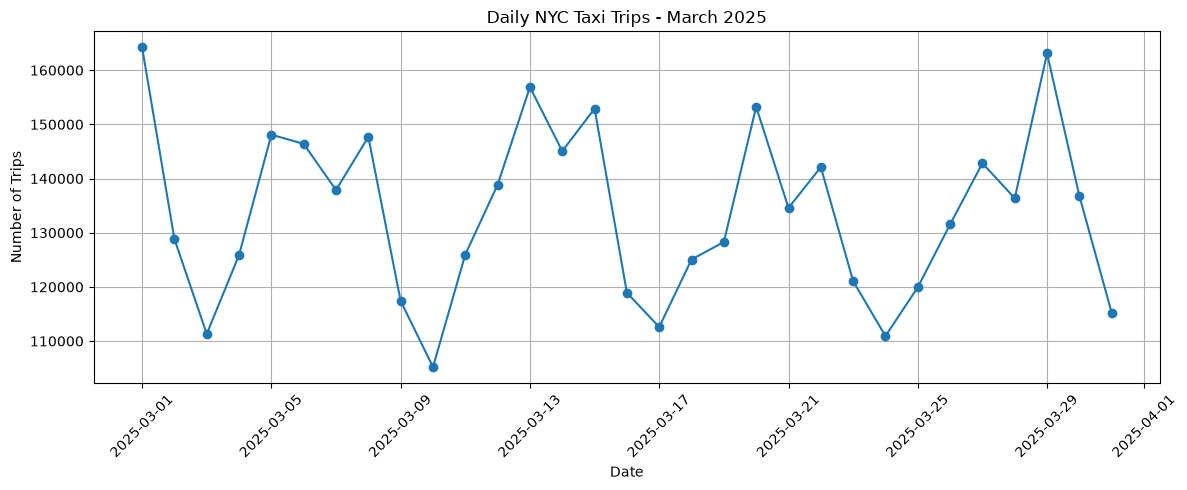

In [150]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(daily_trip.index,
         daily_trip.values,
         marker = "o"
         )

plt.title("Daily NYC Taxi Trips - March 2025")
plt.xlabel("Date")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

“I used Matplotlib to create a line chart showing daily taxi demand throughout March 2025. The chart helped identify demand fluctuations, with March 1 recording the highest number of trips and March 10 recording the lowest.”

**18: Hourly taxi demand visualization**

Business question: At what time of the day do passengers use taxis the most?

You already calculated hourly_trips. Now let's visualize it.

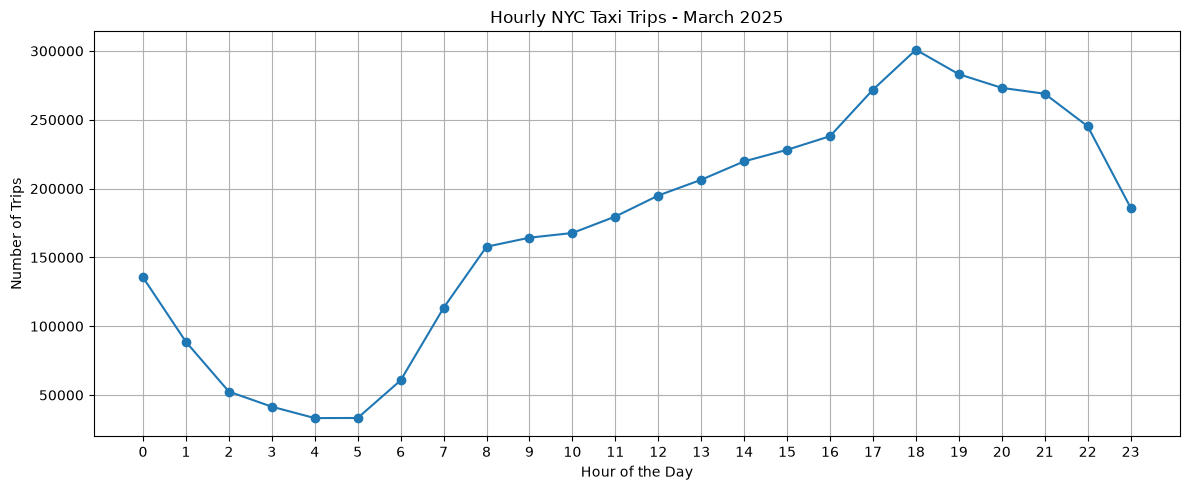

In [151]:
plt.figure(figsize=(12,5))

plt.plot(hourly_trips.index,
         hourly_trips.values,
         marker='o')

plt.title("Hourly NYC Taxi Trips - March 2025")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Trips")

plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()

plt.show()

I grouped taxi trips by pickup hour and visualized the results using a Matplotlib line chart. I found that 6 PM was the busiest hour, with approximately 301,000 trips, while 4 AM and 5 AM had the lowest demand.”

**19: Top 10 pickup and drop-off locations**

Now let's create a chart showing the 10 most popular pickup locations.

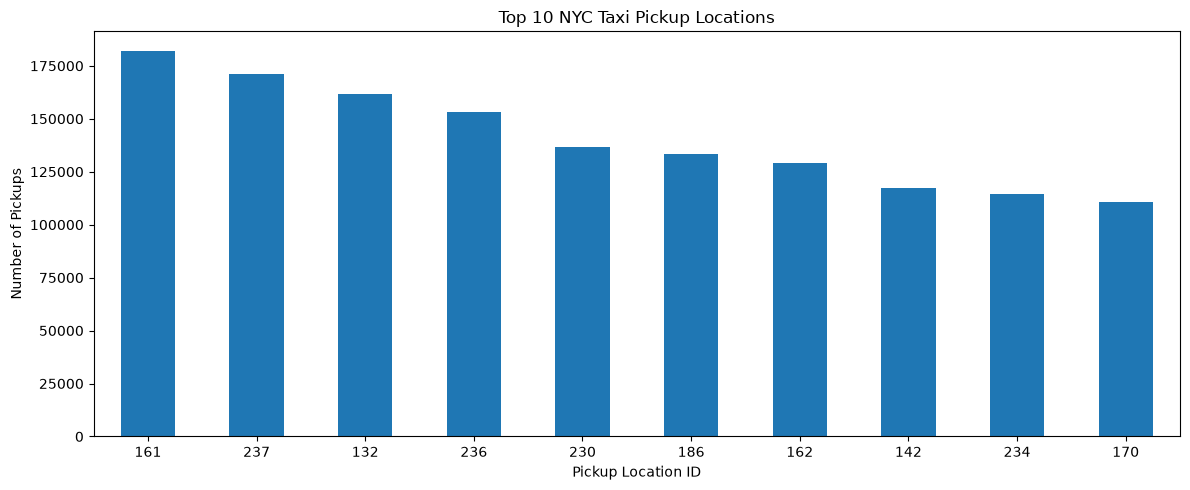

In [153]:
top_10_pickups = pickup_counts.head(10)
plt.figure(figsize=(12, 5))

top_10_pickups.plot(kind="bar")

plt.title("Top 10 NYC Taxi Pickup Locations")
plt.xlabel("Pickup Location ID")
plt.ylabel("Number of Pickups")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

“I used Pandas value_counts to identify the top 10 pickup locations and visualized them using a Matplotlib bar chart. Location ID 161, Midtown Center, recorded the highest pickup volume with 182,169 trips.”

**One more chart: Top 10 drop-off locations**

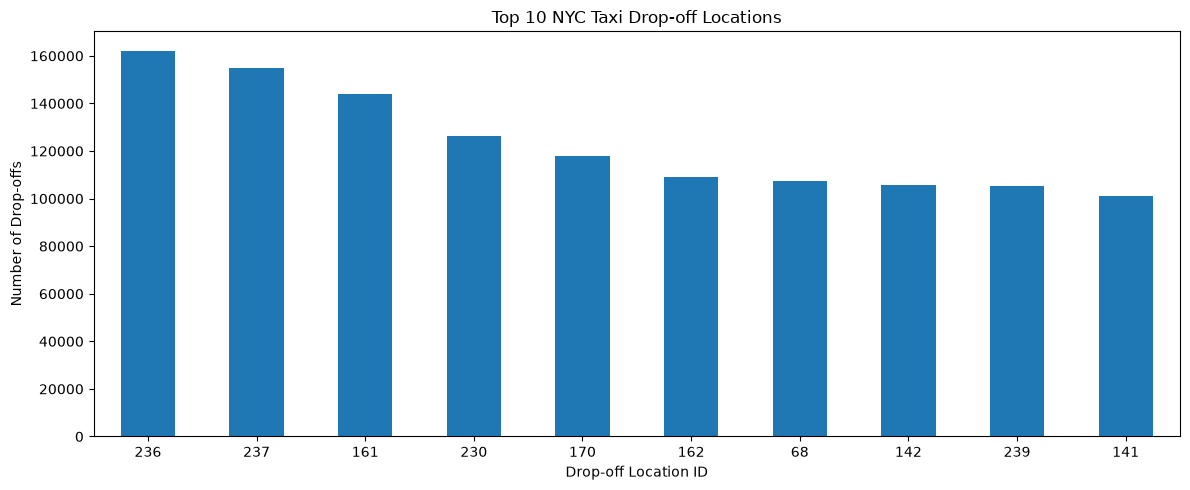

In [154]:
top_10_dropoffs = dropoff_counts.head(10)

plt.figure(figsize=(12, 5))

top_10_dropoffs.plot(kind="bar")

plt.title("Top 10 NYC Taxi Drop-off Locations")
plt.xlabel("Drop-off Location ID")
plt.ylabel("Number of Drop-offs")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

I analyzed the top 10 pickup and drop-off locations separately. Midtown Center (Location ID 161) had the highest pickups, while Upper East Side North (Location ID 236) had the highest drop-offs.”

**Question 20: Payment type distribution**

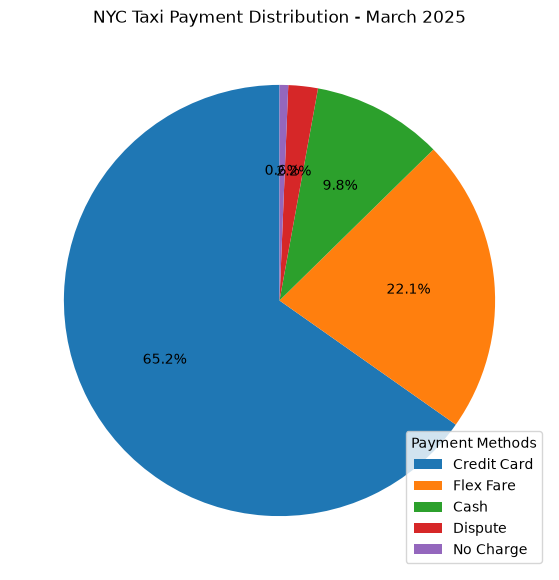

In [ ]:
payment_counts = cleaned_df["payment_type"].value_counts()

payment_labels = {
    0: "Flex Fare",
    1: "Credit Card",
    2: "Cash",
    3: "No Charge",
    4: "Dispute"
}

payment_counts.index = payment_counts.index.map(payment_labels)

plt.figure(figsize=(9, 7))

plt.pie(
    payment_counts,
    autopct="%1.1f%%",
    startangle=90
)

plt.legend(
    payment_counts.index,
    title="Payment Methods",
    loc="lower right"
)

plt.title("NYC Taxi Payment Distribution - March 2025")

plt.show()



### NYC Taxi & Mobility Analytics – Project Explanation

I worked on an NYC Taxi Analytics project using the Yellow Taxi dataset for March 2025.

My main objective was to analyze taxi demand, passenger behavior, popular locations, payment methods, and trip patterns.

First, I used Python and Pandas to load and clean the dataset. I checked missing values, duplicates, incorrect dates, and unusual records. I also calculated trip duration.

After cleaning, I performed exploratory data analysis using Pandas and NumPy. I analyzed daily and hourly demand, popular pickup and drop-off locations, payment methods, trip distances, and borough-wise performance.

I used Matplotlib to create line charts, bar charts, and pie charts to understand the results visually.

One important finding was that Manhattan accounted for approximately 86% of all trips, and 6 PM was the busiest hour.

Through this project, I gained practical experience in data cleaning, data analysis, visualization, and converting data into meaningful business insights.